In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from math import radians, sin, cos, sqrt, atan2

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load final fraud-injected dataset

file_path = "/content/drive/MyDrive/AML_Project/dataset/fraud_transactions_complete.csv"

df = pd.read_csv(file_path)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

df["amount"] = pd.to_numeric(
    df["amount"],
    errors="coerce"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (149994, 15)


/tmp/ipykernel_6389/3160473904.py:5: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [ ]:
# Check geographic columns

print("Geographic columns:")
print([
    "city",
    "state",
    "latitude",
    "longitude"
])

print("\nMissing geographic values:")
print(
    df[
        ["city", "state", "latitude", "longitude"]
    ].isnull().sum()
)

print("\nUnique cities:")
print(df["city"].nunique())

print("\nSample locations:")

display(
    df[
        [
            "transaction_id",
            "city",
            "state",
            "latitude",
            "longitude",
            "fraud_type"
        ]
    ].head(20)
)

Geographic columns:
['city', 'state', 'latitude', 'longitude']

Missing geographic values:
city         0
state        0
latitude     0
longitude    0
dtype: int64

Unique cities:
21

Sample locations:


,transaction_id,city,state,latitude,longitude,fraud_type
0,TX00007570,Delhi,Delhi,28.574159,77.160227,Normal
1,TX00017239,Patna,Bihar,25.642494,85.148727,Normal
2,TX00010111,Bhopal,Madhya Pradesh,23.255729,77.462445,Normal
3,TX00009240,Jaipur,Rajasthan,26.917736,75.807042,Normal
4,TX00009635,Chandigarh,Chandigarh,30.766373,76.738066,Normal
5,TX00015695,Indore,Madhya Pradesh,22.719038,75.832098,Normal
6,TX00002590,Kanpur,Uttar Pradesh,26.412335,80.350768,Normal
7,TX00008049,Lucknow,Uttar Pradesh,26.832182,80.922035,Normal
8,TX00003579,Pune,Maharashtra,18.498925,73.876359,Normal
9,TX00015837,Kanpur,Uttar Pradesh,26.409130,80.324258,Normal


In [ ]:
# Cell 5 — Transactions by City

city_counts = (
    df["city"]
    .value_counts()
    .head(15)
)

print(city_counts)

city
Delhi         13190
Hyderabad     11815
Bengaluru     11116
Jaipur         9639
Patna          8848
Kanpur         8398
Coimbatore     8127
Bhopal         8105
Nagpur         7489
Kochi          7458
Surat          6809
Chandigarh     6804
Lucknow        6788
Kolkata        6631
Ahmedabad      6564
Name: count, dtype: int64


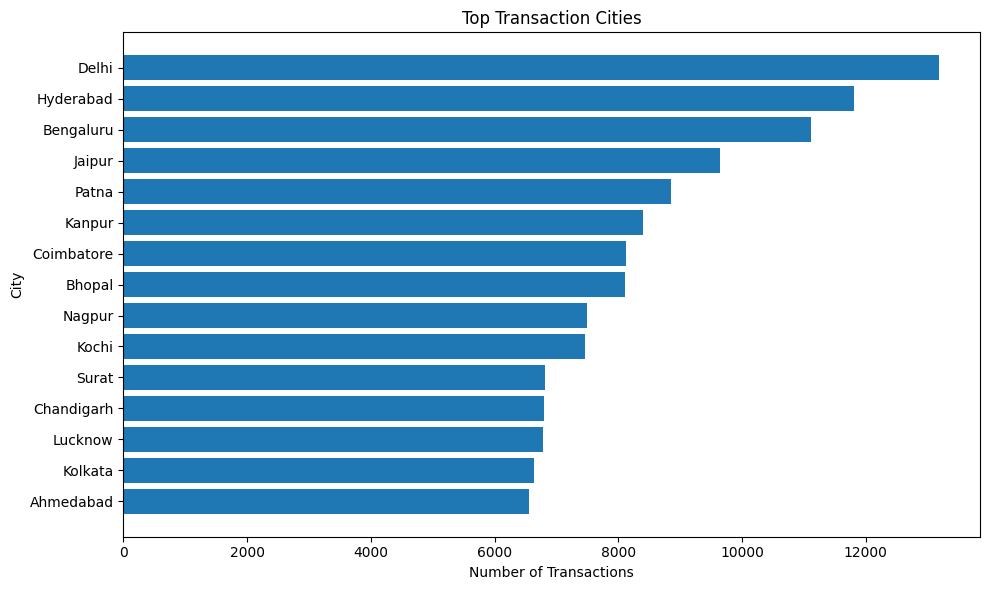

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    city_counts.index[::-1],
    city_counts.values[::-1]
)

plt.xlabel("Number of Transactions")
plt.ylabel("City")
plt.title("Top Transaction Cities")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 6 — Haversine Distance Function

def haversine_distance(
    lat1,
    lon1,
    lat2,
    lon2
):
    """
    Calculate great-circle distance
    between two geographic coordinates.

    Returns distance in kilometers.
    """

    R = 6371.0

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        +
        cos(lat1)
        * cos(lat2)
        * sin(dlon / 2) ** 2
    )

    c = 2 * atan2(
        sqrt(a),
        sqrt(1 - a)
    )

    return R * c


print(
    "Haversine function created successfully!"
)

Haversine function created successfully!


In [ ]:
# Cell 7 — Calculate Consecutive Geographic Distance

df = df.sort_values(
    ["sender", "timestamp"]
).reset_index(drop=True)

df["previous_latitude"] = (
    df.groupby("sender")["latitude"].shift(1)
)

df["previous_longitude"] = (
    df.groupby("sender")["longitude"].shift(1)
)

df["previous_timestamp"] = (
    df.groupby("sender")["timestamp"].shift(1)
)

df["time_gap_minutes"] = (
    (
        df["timestamp"]
        -
        df["previous_timestamp"]
    ).dt.total_seconds() / 60
)

def calculate_row_distance(row):

    if pd.isna(row["previous_latitude"]):
        return 0

    return haversine_distance(
        row["previous_latitude"],
        row["previous_longitude"],
        row["latitude"],
        row["longitude"]
    )

df["distance_km"] = df.apply(
    calculate_row_distance,
    axis=1
)

print("Spatial distance calculation completed!")

display(
    df[
        [
            "sender",
            "timestamp",
            "city",
            "distance_km",
            "time_gap_minutes",
            "fraud_type"
        ]
    ].head(20)
)

Spatial distance calculation completed!


,sender,timestamp,city,distance_km,time_gap_minutes,fraud_type
0,CUST00001,2026-01-01 14:08:47,Ahmedabad,0.000000,NaN,Normal
1,CUST00001,2026-01-02 13:31:46,Kochi,1498.449863,1402.983333,Normal
2,CUST00001,2026-01-02 18:10:34,Bhopal,1481.996460,278.800000,Normal
3,CUST00001,2026-01-02 22:02:10,Visakhapatnam,861.470100,231.600000,Normal
4,CUST00001,2026-01-03 07:55:52,Hyderabad,492.442505,593.700000,Normal
5,CUST00001,2026-01-03 11:30:27,Indore,651.862864,214.583333,Normal
6,CUST00001,2026-01-04 08:02:30,Chandigarh,901.205002,1232.050000,Normal
7,CUST00001,2026-01-05 11:59:43,Hyderabad,1490.180344,1677.216667,Normal
8,CUST00001,2026-01-05 15:33:14,Coimbatore,731.154126,213.516667,Normal
9,CUST00001,2026-01-06 13:11:20,Surat,1220.439357,1298.100000,Normal


In [ ]:
# Cell 8 — Calculate Movement Speed

df["speed_kmph"] = np.where(
    df["time_gap_minutes"] > 0,
    df["distance_km"] /
    (df["time_gap_minutes"] / 60),
    0
)

print("Movement speed calculated!")

display(
    df[
        [
            "sender",
            "timestamp",
            "city",
            "distance_km",
            "time_gap_minutes",
            "speed_kmph",
            "fraud_type"
        ]
    ].sort_values(
        "speed_kmph",
        ascending=False
    ).head(20)
)

Movement speed calculated!


,sender,timestamp,city,distance_km,time_gap_minutes,speed_kmph,fraud_type
80499,CUST02643,2026-01-01 19:46:02,Kochi,1884.677265,0.016667,6.784838e+06,Normal
39084,CUST01273,2026-01-01 20:44:59,Coimbatore,1754.866571,0.016667,6.317520e+06,Normal
75565,CUST02479,2026-01-01 15:06:18,Chandigarh,1600.794396,0.016667,5.762860e+06,Normal
80766,CUST02651,2026-01-01 16:57:05,Bengaluru,1524.693174,0.016667,5.488895e+06,Normal
7559,CUST00247,2026-01-03 08:21:32,Chandigarh,1353.922152,0.016667,4.874120e+06,Normal
25692,CUST00822,2026-01-05 09:45:54,Ahmedabad,1229.112328,0.016667,4.424804e+06,Normal
1812,CUST00065,2026-01-03 18:00:57,Kolkata,1178.045080,0.016667,4.240962e+06,Normal
22731,CUST00726,2026-01-05 13:13:04,Visakhapatnam,1017.884890,0.016667,3.664386e+06,Normal
102496,CUST03391,2026-01-02 12:41:57,Chandigarh,1003.727116,0.016667,3.613418e+06,Normal
56829,CUST01877,2026-01-05 22:31:19,Jaipur,1888.564561,0.033333,3.399416e+06,Normal


In [ ]:
# Cell 9 — Inspect Rapid Geographic Movement transactions

rapid_geo = df[
    df["fraud_type"] == "RapidGeographicMovement"
].copy()

print("RapidGeo transactions:", len(rapid_geo))
print(
    "RapidGeo patterns:",
    rapid_geo["pattern_id"].nunique()
)

display(
    rapid_geo[
        [
            "pattern_id",
            "sender",
            "timestamp",
            "city",
            "latitude",
            "longitude",
            "distance_km",
            "time_gap_minutes",
            "speed_kmph",
            "fraud_type"
        ]
    ]
    .sort_values(["pattern_id", "timestamp"])
    .head(20)
)

RapidGeo transactions: 200
RapidGeo patterns: 50


,pattern_id,sender,timestamp,city,latitude,longitude,distance_km,time_gap_minutes,speed_kmph,fraud_type
43179,RAPIDGEO_001,CUST01413,2026-01-06 02:05:00,Kolkata,22.5726,88.3639,1651.947384,528.683333,187.478660,RapidGeographicMovement
43180,RAPIDGEO_001,CUST01413,2026-01-06 02:09:00,New Delhi,28.6139,77.2090,1303.833469,4.000000,19557.502029,RapidGeographicMovement
43181,RAPIDGEO_001,CUST01413,2026-01-06 02:12:00,Hyderabad,17.3850,78.4867,1255.393411,3.000000,25107.868215,RapidGeographicMovement
43182,RAPIDGEO_001,CUST01413,2026-01-06 02:16:00,Chennai,13.0827,80.2707,515.241634,4.000000,7728.624516,RapidGeographicMovement
105518,RAPIDGEO_002,CUST03489,2026-01-06 05:12:00,Chennai,13.0827,80.2707,1482.596250,2011.033333,44.233864,RapidGeographicMovement
105519,RAPIDGEO_002,CUST03489,2026-01-06 05:17:00,Hyderabad,17.3850,78.4867,515.241634,5.000000,6182.899613,RapidGeographicMovement
105520,RAPIDGEO_002,CUST03489,2026-01-06 05:20:00,New Delhi,28.6139,77.2090,1255.393411,3.000000,25107.868215,RapidGeographicMovement
105521,RAPIDGEO_002,CUST03489,2026-01-06 05:27:00,Kolkata,22.5726,88.3639,1303.833469,7.000000,11175.715445,RapidGeographicMovement
19296,RAPIDGEO_003,CUST00609,2026-01-06 10:49:00,Ahmedabad,23.0225,72.5714,1263.050977,8.400000,9021.792690,RapidGeographicMovement
19297,RAPIDGEO_003,CUST00609,2026-01-06 10:57:00,Chennai,13.0827,80.2707,1371.808916,8.000000,10288.566871,RapidGeographicMovement


In [ ]:
# Cell 10 — Compare spatial behavior

comparison_spatial = (
    df[df["time_gap_minutes"] > 0]
    .groupby("fraud_type")
    .agg(
        transactions=("transaction_id", "count"),
        median_distance_km=("distance_km", "median"),
        max_distance_km=("distance_km", "max"),
        median_time_gap_min=("time_gap_minutes", "median"),
        median_speed_kmph=("speed_kmph", "median"),
        max_speed_kmph=("speed_kmph", "max")
    )
    .reset_index()
)

display(comparison_spatial)

,fraud_type,transactions,median_distance_km,max_distance_km,median_time_gap_min,median_speed_kmph,max_speed_kmph
0,Circular,200,855.377909,2085.123275,410.125000,120.643843,1.242854e+04
1,Layering,200,813.859806,2085.123275,442.383333,109.049238,1.324060e+05
2,Mule,300,854.845733,2085.123275,339.775000,149.426413,5.440941e+04
3,Normal,143534,927.242526,2324.456299,120.991667,388.659206,6.784838e+06
4,RapidGeographicMovement,200,1095.146607,1888.888577,6.000000,10143.820628,3.511595e+04
5,Smurfing,250,0.000000,2083.053610,6.000000,0.000000,2.610628e+04
6,Structuring,299,0.000000,2080.630017,8.000000,0.000000,2.090353e+04


In [ ]:
# Cell 11 — Detect rapid geographic movement candidates

RAPID_TIME_THRESHOLD = 10       # minutes
RAPID_DISTANCE_THRESHOLD = 500  # km

rapid_candidates = df[
    (df["time_gap_minutes"] > 0) &
    (df["time_gap_minutes"] <= RAPID_TIME_THRESHOLD) &
    (df["distance_km"] >= RAPID_DISTANCE_THRESHOLD)
].copy()

print(
    "Rapid geographic candidates:",
    len(rapid_candidates)
)

print("\nFraud-type distribution:")
print(
    rapid_candidates["fraud_type"].value_counts()
)

display(
    rapid_candidates[
        [
            "sender",
            "timestamp",
            "city",
            "distance_km",
            "time_gap_minutes",
            "speed_kmph",
            "fraud_type",
            "pattern_id"
        ]
    ]
    .sort_values("distance_km", ascending=False)
    .head(20)
)

Rapid geographic candidates: 7471

Fraud-type distribution:
fraud_type
Normal                     7316
RapidGeographicMovement     139
Mule                          5
Structuring                   4
Layering                      3
Smurfing                      3
Circular                      1
Name: count, dtype: int64


,sender,timestamp,city,distance_km,time_gap_minutes,speed_kmph,fraud_type,pattern_id
120426,CUST03999,2026-01-02 18:50:17,Kochi,2322.535816,3.383333,41187.827280,Normal,NaN
48728,CUST01592,2026-01-06 16:39:04,Kochi,2322.434440,4.783333,29131.581831,Normal,NaN
91390,CUST03012,2026-01-02 21:46:39,Chandigarh,2321.927888,1.950000,71443.935021,Normal,NaN
124387,CUST04122,2026-01-02 18:16:08,Chandigarh,2318.717142,6.283333,22141.596051,Normal,NaN
87085,CUST02857,2026-01-04 11:23:42,Chandigarh,2318.409035,7.416667,18755.668600,Normal,NaN
45196,CUST01479,2026-01-01 20:26:45,Chandigarh,2318.200606,3.083333,45110.930707,Normal,NaN
49717,CUST01629,2026-01-02 12:22:37,Chandigarh,2317.972777,0.583333,238420.057027,Normal,NaN
3656,CUST00120,2026-01-06 20:28:18,Chandigarh,2317.658396,1.183333,117515.073592,Normal,NaN
81448,CUST02673,2026-01-03 16:21:08,Kochi,2317.538459,9.783333,14213.183052,Normal,NaN
7390,CUST00240,2026-01-01 07:15:27,Kochi,2317.273341,5.683333,24463.882774,Normal,NaN


In [ ]:
# Cell 12 — RapidGeo Detection Evaluation

planted_rapid_patterns = set(
    df.loc[
        df["fraud_type"] == "RapidGeographicMovement",
        "pattern_id"
    ].dropna()
)

detected_rapid_patterns = set(
    rapid_candidates.loc[
        rapid_candidates["fraud_type"] == "RapidGeographicMovement",
        "pattern_id"
    ].dropna()
)

matched_patterns = (
    planted_rapid_patterns &
    detected_rapid_patterns
)

print("Planted RapidGeo patterns:",
      len(planted_rapid_patterns))

print("Detected RapidGeo patterns:",
      len(detected_rapid_patterns))

print("Matched RapidGeo patterns:",
      len(matched_patterns))

if planted_rapid_patterns:
    coverage = (
        len(matched_patterns) /
        len(planted_rapid_patterns)
    ) * 100

    print(
        f"RapidGeo pattern coverage: {coverage:.2f}%"
    )

Planted RapidGeo patterns: 50
Detected RapidGeo patterns: 50
Matched RapidGeo patterns: 50
RapidGeo pattern coverage: 100.00%


In [ ]:
# Cell 13 — RapidGeo Threshold Experiment

thresholds = [
    (500, 10),
    (750, 10),
    (1000, 10),
    (1250, 10),
    (1500, 10),
    (1000, 8),
    (1000, 6),
    (1250, 8),
    (1500, 8)
]

results = []

planted_patterns = set(
    df.loc[
        df["fraud_type"] == "RapidGeographicMovement",
        "pattern_id"
    ].dropna()
)

for distance_threshold, time_threshold in thresholds:

    candidates = df[
        (df["time_gap_minutes"] > 0) &
        (df["time_gap_minutes"] <= time_threshold) &
        (df["distance_km"] >= distance_threshold)
    ]

    detected_patterns = set(
        candidates.loc[
            candidates["fraud_type"] == "RapidGeographicMovement",
            "pattern_id"
        ].dropna()
    )

    matched = (
        planted_patterns &
        detected_patterns
    )

    tp = len(
        candidates[
            candidates["fraud_type"]
            == "RapidGeographicMovement"
        ]
    )

    fp = len(
        candidates[
            candidates["fraud_type"]
            != "RapidGeographicMovement"
        ]
    )

    precision = (
        tp / (tp + fp) * 100
        if (tp + fp) > 0
        else 0
    )

    recall = (
        len(matched) /
        len(planted_patterns) * 100
        if planted_patterns
        else 0
    )

    results.append({
        "distance_threshold_km":
            distance_threshold,

        "time_threshold_min":
            time_threshold,

        "candidates":
            len(candidates),

        "rapidgeo_detected":
            tp,

        "false_positives":
            fp,

        "precision_percent":
            precision,

        "recall_percent":
            recall
    })

threshold_results = pd.DataFrame(results)

display(
    threshold_results.sort_values(
        ["recall_percent", "precision_percent"],
        ascending=False
    )
)

,distance_threshold_km,time_threshold_min,candidates,rapidgeo_detected,false_positives,precision_percent,recall_percent
1,750,10,5922,120,5802,2.026342,100.0
0,500,10,7471,139,7332,1.860527,100.0
5,1000,8,3447,94,3353,2.727009,96.0
2,1000,10,4280,95,4185,2.219626,96.0
7,1250,8,2162,68,2094,3.145236,84.0
3,1250,10,2689,69,2620,2.566010,84.0
6,1000,6,2574,64,2510,2.486402,80.0
8,1500,8,1310,33,1277,2.519084,50.0
4,1500,10,1626,33,1593,2.029520,50.0


In [ ]:
# Cell 14 — Calculate F1 Score

threshold_results["f1_percent"] = (
    2
    * threshold_results["precision_percent"]
    * threshold_results["recall_percent"]
    /
    (
        threshold_results["precision_percent"]
        +
        threshold_results["recall_percent"]
    )
).fillna(0)

display(
    threshold_results.sort_values(
        "f1_percent",
        ascending=False
    )
)

,distance_threshold_km,time_threshold_min,candidates,rapidgeo_detected,false_positives,precision_percent,recall_percent,f1_percent
7,1250,8,2162,68,2094,3.145236,84.0,6.063437
5,1000,8,3447,94,3353,2.727009,96.0,5.303369
3,1250,10,2689,69,2620,2.566010,84.0,4.979895
6,1000,6,2574,64,2510,2.486402,80.0,4.822909
8,1500,8,1310,33,1277,2.519084,50.0,4.796512
2,1000,10,4280,95,4185,2.219626,96.0,4.338931
1,750,10,5922,120,5802,2.026342,100.0,3.972195
4,1500,10,1626,33,1593,2.029520,50.0,3.900709
0,500,10,7471,139,7332,1.860527,100.0,3.653088


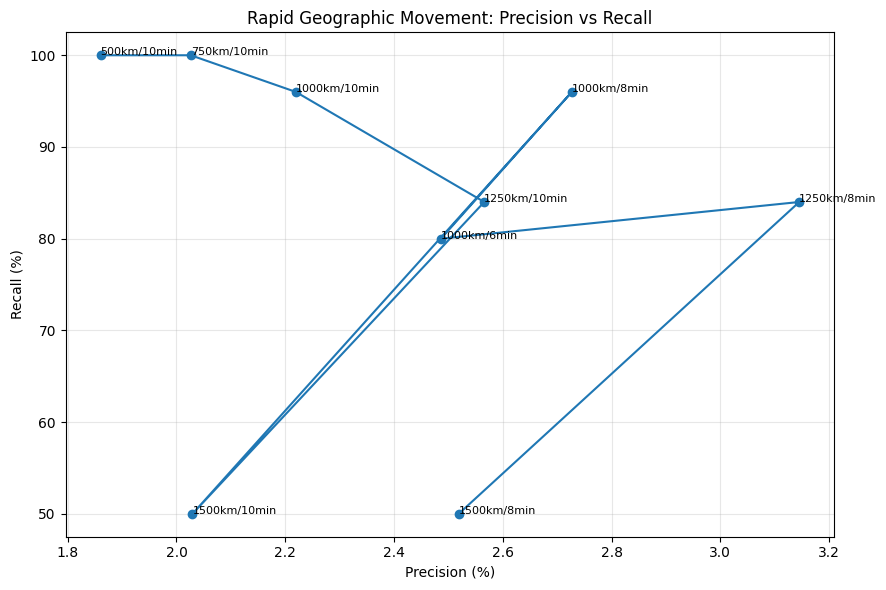

In [ ]:
# Cell 15 — Precision vs Recall

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["precision_percent"],
    threshold_results["recall_percent"],
    marker="o"
)

for _, row in threshold_results.iterrows():

    label = (
        f"{int(row['distance_threshold_km'])}km/"
        f"{int(row['time_threshold_min'])}min"
    )

    plt.annotate(
        label,
        (
            row["precision_percent"],
            row["recall_percent"]
        ),
        fontsize=8
    )

plt.xlabel("Precision (%)")
plt.ylabel("Recall (%)")
plt.title("Rapid Geographic Movement: Precision vs Recall")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Cell 16 — Pattern-level Precision, Recall and F1

threshold_results_pattern = []

planted_patterns = set(
    df.loc[
        df["fraud_type"] == "RapidGeographicMovement",
        "pattern_id"
    ].dropna()
)

for distance_threshold, time_threshold in thresholds:

    candidates = df[
        (df["time_gap_minutes"] > 0) &
        (df["time_gap_minutes"] <= time_threshold) &
        (df["distance_km"] >= distance_threshold)
    ]

    # Patterns that have at least one detected transaction
    detected_patterns = set(
        candidates["pattern_id"].dropna()
    )

    # Only RapidGeo planted patterns count as true positives
    detected_rapid_patterns = (
        detected_patterns &
        planted_patterns
    )

    # Pattern-level TP and FN
    tp = len(detected_rapid_patterns)
    fn = len(planted_patterns - detected_rapid_patterns)

    # Any non-RapidGeo pattern detected = false positive pattern
    false_positive_patterns = (
        detected_patterns - planted_patterns
    )

    fp = len(false_positive_patterns)

    precision = (
        tp / (tp + fp) * 100
        if (tp + fp) > 0 else 0
    )

    recall = (
        tp / (tp + fn) * 100
        if (tp + fn) > 0 else 0
    )

    f1 = (
        2 * precision * recall /
        (precision + recall)
        if (precision + recall) > 0 else 0
    )

    threshold_results_pattern.append({
        "distance_km": distance_threshold,
        "time_minutes": time_threshold,
        "TP_patterns": tp,
        "FP_patterns": fp,
        "FN_patterns": fn,
        "precision_%": precision,
        "recall_%": recall,
        "F1_%": f1
    })

pattern_threshold_results = pd.DataFrame(
    threshold_results_pattern
)

display(
    pattern_threshold_results.sort_values(
        "F1_%",
        ascending=False
    )
)

,distance_km,time_minutes,TP_patterns,FP_patterns,FN_patterns,precision_%,recall_%,F1_%
5,1000,8,48,2,2,96.000000,96.0,96.000000
2,1000,10,48,4,2,92.307692,96.0,94.117647
1,750,10,50,8,0,86.206897,100.0,92.592593
7,1250,8,42,2,8,95.454545,84.0,89.361702
6,1000,6,40,1,10,97.560976,80.0,87.912088
3,1250,10,42,4,8,91.304348,84.0,87.500000
0,500,10,50,15,0,76.923077,100.0,86.956522
4,1500,10,25,1,25,96.153846,50.0,65.789474
8,1500,8,25,1,25,96.153846,50.0,65.789474


In [ ]:
# Cell 17 — Select Best RapidGeo Threshold

best_threshold = (
    pattern_threshold_results
    .sort_values("F1_%", ascending=False)
    .iloc[0]
)

print("BEST RAPID GEO THRESHOLD")
print("------------------------")

print(
    "Distance threshold:",
    best_threshold["distance_km"],
    "km"
)

print(
    "Time threshold:",
    best_threshold["time_minutes"],
    "minutes"
)

print(
    "Precision:",
    f"{best_threshold['precision_%']:.2f}%"
)

print(
    "Recall:",
    f"{best_threshold['recall_%']:.2f}%"
)

print(
    "F1 Score:",
    f"{best_threshold['F1_%']:.2f}%"
)

BEST RAPID GEO THRESHOLD
------------------------
Distance threshold: 1000.0 km
Time threshold: 8.0 minutes
Precision: 96.00%
Recall: 96.00%
F1 Score: 96.00%


In [ ]:
# Cell 18 — Final Rapid Geographic Movement Detector

BEST_DISTANCE = best_threshold["distance_km"]
BEST_TIME = best_threshold["time_minutes"]

rapid_geo_detected = df[
    (df["time_gap_minutes"] > 0) &
    (df["time_gap_minutes"] <= BEST_TIME) &
    (df["distance_km"] >= BEST_DISTANCE)
].copy()

print("Final RapidGeo detector")
print("-----------------------")

print("Distance threshold:", BEST_DISTANCE, "km")
print("Time threshold:", BEST_TIME, "minutes")

print(
    "\nCandidate transactions:",
    len(rapid_geo_detected)
)

print("\nFraud distribution:")
print(
    rapid_geo_detected["fraud_type"]
    .value_counts()
)

display(
    rapid_geo_detected[
        [
            "sender",
            "timestamp",
            "city",
            "distance_km",
            "time_gap_minutes",
            "speed_kmph",
            "fraud_type",
            "pattern_id"
        ]
    ]
    .head(20)
)

Final RapidGeo detector
-----------------------
Distance threshold: 1000.0 km
Time threshold: 8.0 minutes

Candidate transactions: 3447

Fraud distribution:
fraud_type
Normal                     3351
RapidGeographicMovement      94
Smurfing                      1
Mule                          1
Name: count, dtype: int64


,sender,timestamp,city,distance_km,time_gap_minutes,speed_kmph,fraud_type,pattern_id
47,CUST00004,2026-01-01 09:38:40,Ahmedabad,1308.127468,3.366667,23313.162796,Normal,NaN
115,CUST00005,2026-01-05 14:44:58,Surat,1617.116822,5.216667,18599.426706,Normal,NaN
161,CUST00007,2026-01-04 17:29:52,Kolkata,1604.204529,5.666667,16985.695015,Normal,NaN
201,CUST00008,2026-01-03 20:37:09,Ahmedabad,1305.347273,2.550000,30714.053490,Normal,NaN
253,CUST00010,2026-01-01 21:55:46,Bhopal,1481.996460,3.850000,23096.048735,Normal,NaN
322,CUST00012,2026-01-04 21:26:47,Delhi,1144.600431,2.666667,25753.509705,Normal,NaN
326,CUST00012,2026-01-05 15:05:18,Bengaluru,1561.827375,7.383333,12692.050906,Normal,NaN
353,CUST00013,2026-01-02 17:57:20,Ahmedabad,1404.652027,2.650000,31803.442125,Normal,NaN
356,CUST00013,2026-01-02 19:14:10,Mumbai,1142.177437,1.066667,64247.480842,Normal,NaN
449,CUST00015,2026-01-07 18:37:50,Bengaluru,1044.480699,3.383333,18522.810419,Normal,NaN


In [ ]:
# Cell 19 — Prepare coordinates for K-Means

spatial_data = df[
    [
        "transaction_id",
        "city",
        "state",
        "latitude",
        "longitude",
        "fraud_type"
    ]
].dropna(
    subset=["latitude", "longitude"]
).copy()

print("Spatial records:", len(spatial_data))

print(
    "Unique coordinates:",
    spatial_data[
        ["latitude", "longitude"]
    ].drop_duplicates().shape[0]
)

display(spatial_data.head())

Spatial records: 149994
Unique coordinates: 208


,transaction_id,city,state,latitude,longitude,fraud_type
0,TX00000001,Ahmedabad,Gujarat,22.976326,72.581057,Normal
1,TX00021204,Kochi,Kerala,9.964463,76.246925,Normal
2,TX00021206,Bhopal,Madhya Pradesh,23.245268,77.418588,Normal
3,TX00021205,Visakhapatnam,Andhra Pradesh,17.674838,83.169090,Normal
4,TX00042517,Hyderabad,Telangana,17.378639,78.535124,Normal


In [ ]:
# Cell 20 — K-Means

from sklearn.cluster import KMeans

print("K-Means imported successfully!")

K-Means imported successfully!


In [ ]:
# Cell 21 — Configure K-Means

K = 8

coordinates = spatial_data[
    ["latitude", "longitude"]
].values

kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

spatial_data["cluster"] = kmeans.fit_predict(
    coordinates
)

print("K-Means clustering completed!")
print("Number of clusters:", K)

print("\nCluster distribution:")
print(
    spatial_data["cluster"]
    .value_counts()
    .sort_index()
)

K-Means clustering completed!
Number of clusters: 8

Cluster distribution:
cluster
0     5960
1    29659
2    11815
3    23709
4    28907
5    15479
6    19279
7    15186
Name: count, dtype: int64


In [ ]:
# Cell 22 — Cluster Centers

cluster_centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=["latitude", "longitude"]
)

cluster_centers["cluster"] = range(K)

print("Cluster centers:")
display(cluster_centers)

Cluster centers:


,latitude,longitude,cluster
0,17.670100,83.235674,0
1,28.545764,76.650376,1
2,17.387118,78.495093,2
3,20.660181,72.966138,3
4,11.646594,77.274100,4
5,24.300092,86.520319,5
6,22.327719,77.764194,6
7,26.625832,80.601033,7


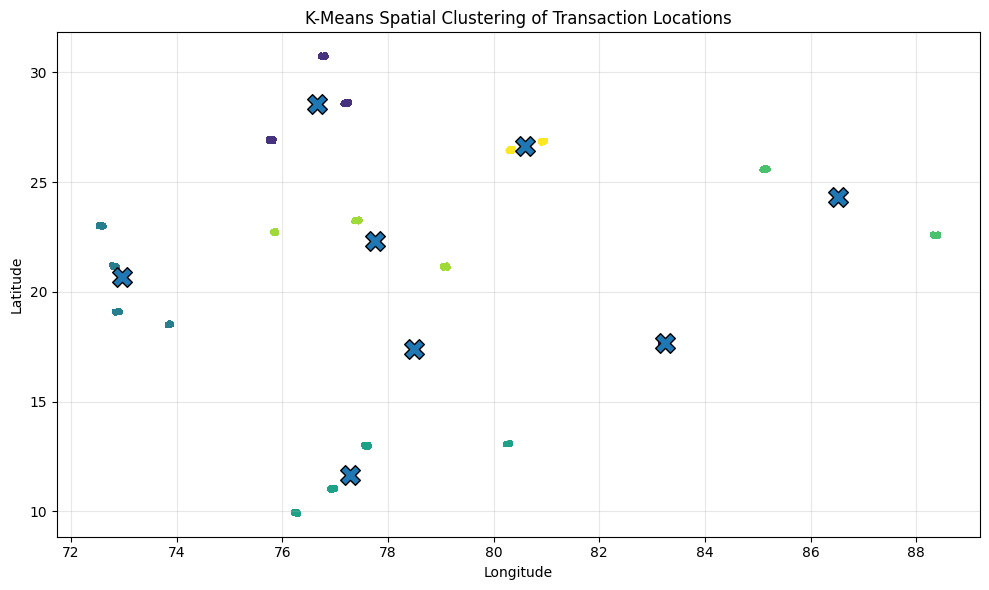

In [ ]:
# Cell 23 — K-Means Spatial Clusters

plt.figure(figsize=(10, 6))

plt.scatter(
    spatial_data["longitude"],
    spatial_data["latitude"],
    c=spatial_data["cluster"],
    s=8,
    alpha=0.5
)

plt.scatter(
    cluster_centers["longitude"],
    cluster_centers["latitude"],
    marker="X",
    s=200,
    edgecolor="black"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("K-Means Spatial Clustering of Transaction Locations")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Cell 24 — Fraud Distribution by Spatial Cluster

cluster_fraud = pd.crosstab(
    spatial_data["cluster"],
    spatial_data["fraud_type"]
)

display(cluster_fraud)

fraud_type,Circular,Layering,Mule,Normal,RapidGeographicMovement,Smurfing,Structuring
cluster,,,,,,,
0,0,0,0,5960,0,0,0
1,200,200,300,28356,53,250,300
2,0,0,0,11784,31,0,0
3,0,0,0,23667,42,0,0
4,0,0,0,28857,50,0,0
5,0,0,0,15455,24,0,0
6,0,0,0,19279,0,0,0
7,0,0,0,15186,0,0,0


In [ ]:
# Cell 25 — Fraud Rate by Spatial Cluster

fraud_types = [
    "Layering",
    "Smurfing",
    "Structuring",
    "Circular",
    "Mule",
    "RapidGeographicMovement"
]

existing_fraud_types = [
    x for x in fraud_types
    if x in spatial_data["fraud_type"].unique()
]

cluster_summary = (
    spatial_data
    .groupby("cluster")
    .agg(
        total_transactions=(
            "transaction_id",
            "count"
        ),
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean")
    )
    .reset_index()
)

fraud_counts = (
    spatial_data[
        spatial_data["fraud_type"].isin(
            existing_fraud_types
        )
    ]
    .groupby("cluster")
    .size()
    .reset_index(
        name="fraud_transactions"
    )
)

cluster_summary = cluster_summary.merge(
    fraud_counts,
    on="cluster",
    how="left"
)

cluster_summary["fraud_transactions"] = (
    cluster_summary[
        "fraud_transactions"
    ].fillna(0)
)

cluster_summary["fraud_rate_%"] = (
    cluster_summary["fraud_transactions"]
    /
    cluster_summary["total_transactions"]
    * 100
)

cluster_summary = cluster_summary.sort_values(
    "fraud_rate_%",
    ascending=False
)

display(cluster_summary)

,cluster,total_transactions,latitude,longitude,fraud_transactions,fraud_rate_%
1,1,29659,28.545764,76.650376,1303.0,4.393270
2,2,11815,17.387118,78.495093,31.0,0.262378
3,3,23709,20.660181,72.966138,42.0,0.177148
4,4,28907,11.646594,77.274100,50.0,0.172968
5,5,15479,24.300092,86.520319,24.0,0.155049
0,0,5960,17.670100,83.235674,0.0,0.000000
6,6,19279,22.327719,77.764194,0.0,0.000000
7,7,15186,26.625832,80.601033,0.0,0.000000


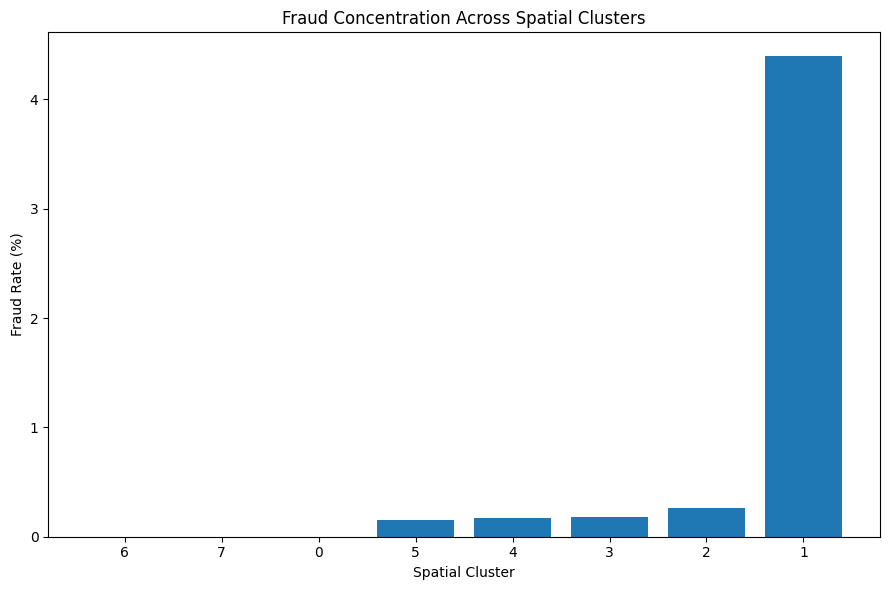

In [ ]:
# Cell 26 — Fraud Rate by Spatial Cluster

plot_df = cluster_summary.sort_values(
    "fraud_rate_%"
)

plt.figure(figsize=(9, 6))

plt.bar(
    plot_df["cluster"].astype(str),
    plot_df["fraud_rate_%"]
)

plt.xlabel("Spatial Cluster")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Concentration Across Spatial Clusters")

plt.tight_layout()
plt.show()

Highest-risk spatial cluster: 1.0


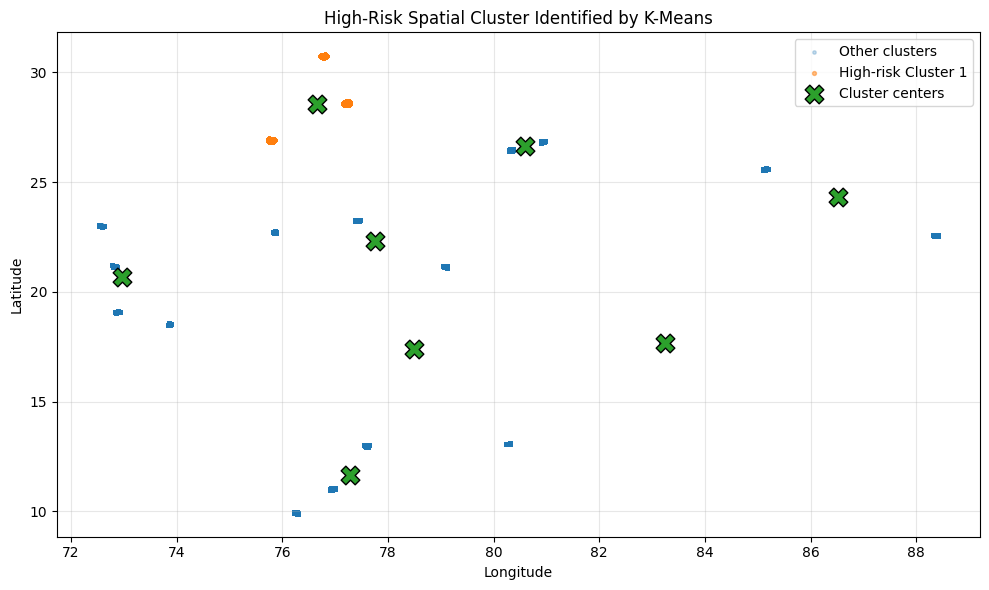

In [ ]:
# Cell 27 — Highlight Highest-Fraud Spatial Cluster

highest_risk_cluster = cluster_summary.iloc[0]["cluster"]

print("Highest-risk spatial cluster:", highest_risk_cluster)

risk_cluster = spatial_data[
    spatial_data["cluster"] == highest_risk_cluster
]

normal_clusters = spatial_data[
    spatial_data["cluster"] != highest_risk_cluster
]

plt.figure(figsize=(10, 6))

plt.scatter(
    normal_clusters["longitude"],
    normal_clusters["latitude"],
    s=6,
    alpha=0.25,
    label="Other clusters"
)

plt.scatter(
    risk_cluster["longitude"],
    risk_cluster["latitude"],
    s=8,
    alpha=0.5,
    label=f"High-risk Cluster {int(highest_risk_cluster)}"
)

plt.scatter(
    cluster_centers["longitude"],
    cluster_centers["latitude"],
    marker="X",
    s=180,
    edgecolor="black",
    label="Cluster centers"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("High-Risk Spatial Cluster Identified by K-Means")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

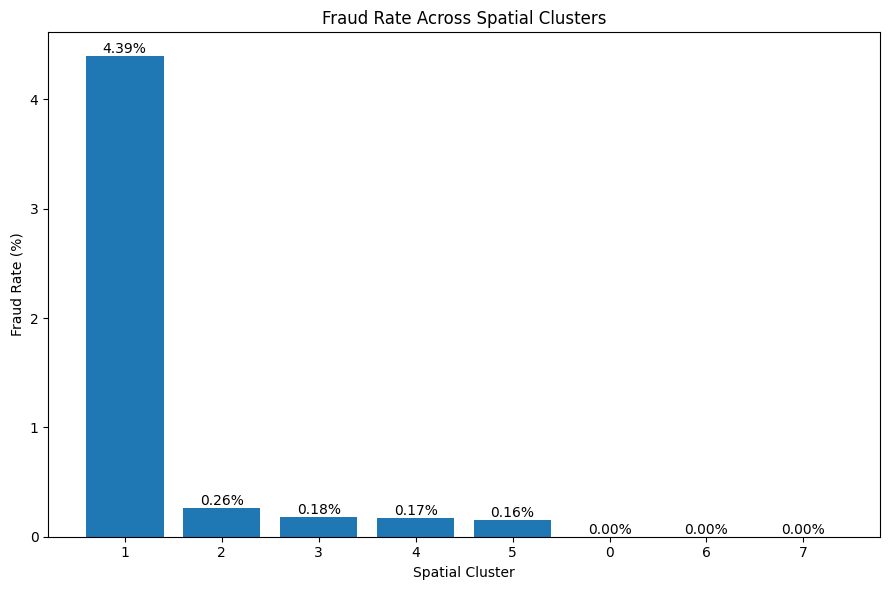

In [ ]:
# Cell 28 — Spatial Cluster Fraud Rate

plot_df = cluster_summary.sort_values(
    "fraud_rate_%",
    ascending=False
)

plt.figure(figsize=(9, 6))

bars = plt.bar(
    plot_df["cluster"].astype(str),
    plot_df["fraud_rate_%"]
)

plt.xlabel("Spatial Cluster")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate Across Spatial Clusters")

for bar, value in zip(
    bars,
    plot_df["fraud_rate_%"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
# Cell 29 — Memory-efficient spatial data

spatial_points = (
    df[
        [
            "city",
            "state",
            "latitude",
            "longitude"
        ]
    ]
    .dropna(
        subset=[
            "latitude",
            "longitude"
        ]
    )
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    "Unique geographic locations:",
    len(spatial_points)
)

display(spatial_points.head(20))

Unique geographic locations: 209


,city,state,latitude,longitude
0,Ahmedabad,Gujarat,22.976326,72.581057
1,Kochi,Kerala,9.964463,76.246925
2,Bhopal,Madhya Pradesh,23.245268,77.418588
3,Visakhapatnam,Andhra Pradesh,17.674838,83.169090
4,Hyderabad,Telangana,17.378639,78.535124
5,Indore,Madhya Pradesh,22.670865,75.849706
6,Chandigarh,Chandigarh,30.729022,76.822302
7,Hyderabad,Telangana,17.415713,78.509673
8,Coimbatore,Tamil Nadu,11.007408,76.989173
9,Surat,Gujarat,21.214806,72.783053


In [ ]:
# Cell 30 — Transaction density by location

location_counts = (
    df.groupby(
        [
            "city",
            "state",
            "latitude",
            "longitude"
        ]
    )
    .size()
    .reset_index(
        name="transaction_count"
    )
)

spatial_points = spatial_points.merge(
    location_counts,
    on=[
        "city",
        "state",
        "latitude",
        "longitude"
    ],
    how="left"
)

print("Location statistics prepared!")

display(
    spatial_points.sort_values(
        "transaction_count",
        ascending=False
    ).head(20)
)

Location statistics prepared!


,city,state,latitude,longitude,transaction_count
181,Delhi,Delhi,28.613900,77.209000,1250
103,Mumbai,Maharashtra,19.050866,72.846721,821
29,Surat,Gujarat,21.127800,72.850161,809
21,Nagpur,Maharashtra,21.190713,79.046718,806
31,Kanpur,Uttar Pradesh,26.422364,80.301813,803
184,Kanpur,Uttar Pradesh,26.443484,80.284802,799
124,Bengaluru,Karnataka,13.015493,77.558029,796
6,Chandigarh,Chandigarh,30.729022,76.822302,795
53,Nagpur,Maharashtra,21.127355,79.112488,794
65,Delhi,Delhi,28.661561,77.211464,792


In [ ]:
# Cell 31 — Memory-efficient DBSCAN

from sklearn.cluster import DBSCAN

EARTH_RADIUS_KM = 6371.0088

EPS_KM = 100
MIN_SAMPLES = 2

coordinates_rad = np.radians(
    spatial_points[
        [
            "latitude",
            "longitude"
        ]
    ].values
)

eps_radians = (
    EPS_KM /
    EARTH_RADIUS_KM
)

dbscan = DBSCAN(
    eps=eps_radians,
    min_samples=MIN_SAMPLES,
    metric="haversine",
    algorithm="ball_tree"
)

spatial_points["dbscan_cluster"] = (
    dbscan.fit_predict(
        coordinates_rad
    )
)

print("DBSCAN completed successfully!")

print(
    "Unique geographic points:",
    len(spatial_points)
)

print(
    "Number of spatial clusters:",
    spatial_points[
        spatial_points["dbscan_cluster"] != -1
    ]["dbscan_cluster"].nunique()
)

print(
    "Spatial outlier locations:",
    (
        spatial_points["dbscan_cluster"] == -1
    ).sum()
)

DBSCAN completed successfully!
Unique geographic points: 209
Number of spatial clusters: 19
Spatial outlier locations: 0


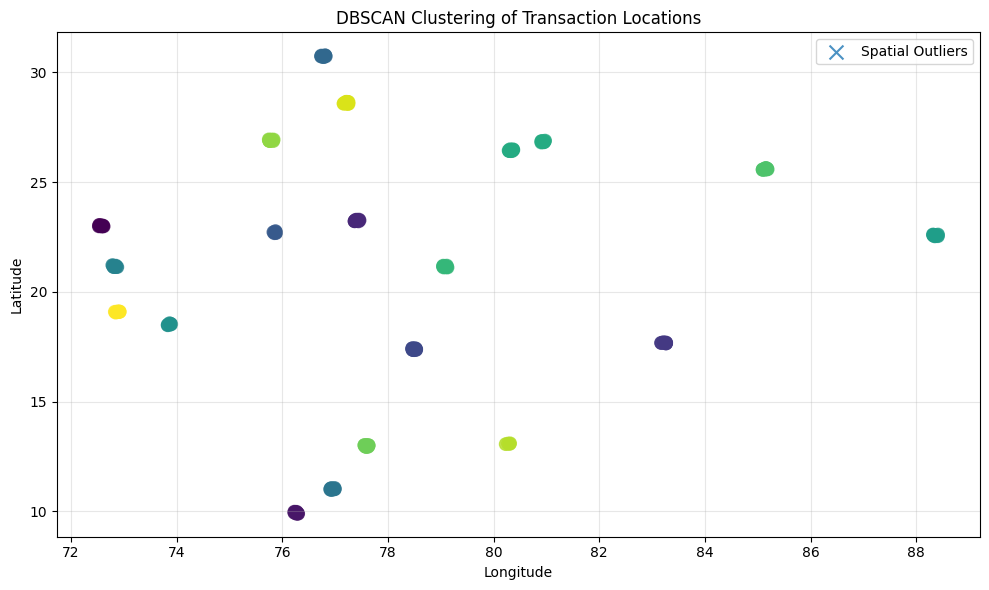

In [ ]:
# Cell 32 — DBSCAN Spatial Clusters

plt.figure(figsize=(10, 6))

clustered_points = spatial_points[
    spatial_points["dbscan_cluster"] != -1
]

noise_points = spatial_points[
    spatial_points["dbscan_cluster"] == -1
]

plt.scatter(
    clustered_points["longitude"],
    clustered_points["latitude"],
    c=clustered_points["dbscan_cluster"],
    s=80,
    alpha=0.8
)

plt.scatter(
    noise_points["longitude"],
    noise_points["latitude"],
    marker="x",
    s=100,
    alpha=0.8,
    label="Spatial Outliers"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "DBSCAN Clustering of Transaction Locations"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

In [ ]:
# Cell 33 — Assign DBSCAN cluster to transactions

df_spatial = df.merge(
    spatial_points[
        [
            "city",
            "state",
            "latitude",
            "longitude",
            "dbscan_cluster"
        ]
    ],
    on=[
        "city",
        "state",
        "latitude",
        "longitude"
    ],
    how="left"
)

print(
    "Transactions mapped to DBSCAN clusters:",
    len(df_spatial)
)

display(
    df_spatial[
        [
            "transaction_id",
            "city",
            "state",
            "dbscan_cluster",
            "fraud_type"
        ]
    ].head(10)
)

Transactions mapped to DBSCAN clusters: 149994


,transaction_id,city,state,dbscan_cluster,fraud_type
0,TX00000001,Ahmedabad,Gujarat,0,Normal
1,TX00021204,Kochi,Kerala,1,Normal
2,TX00021206,Bhopal,Madhya Pradesh,2,Normal
3,TX00021205,Visakhapatnam,Andhra Pradesh,3,Normal
4,TX00042517,Hyderabad,Telangana,4,Normal
5,TX00042516,Indore,Madhya Pradesh,5,Normal
6,TX00063995,Chandigarh,Chandigarh,6,Normal
7,TX00084834,Hyderabad,Telangana,4,Normal
8,TX00084833,Coimbatore,Tamil Nadu,7,Normal
9,TX00106302,Surat,Gujarat,8,Normal


In [ ]:
# Cell 34 — Fraud concentration by DBSCAN cluster

fraud_types = [
    "Layering",
    "Smurfing",
    "Structuring",
    "Circular",
    "Mule",
    "RapidGeographicMovement"
]

existing_fraud_types = [
    x for x in fraud_types
    if x in df_spatial["fraud_type"].unique()
]

dbscan_summary = (
    df_spatial
    .groupby("dbscan_cluster")
    .agg(
        transactions=(
            "transaction_id",
            "count"
        ),
        latitude=(
            "latitude",
            "mean"
        ),
        longitude=(
            "longitude",
            "mean"
        )
    )
    .reset_index()
)

fraud_counts = (
    df_spatial[
        df_spatial["fraud_type"]
        .isin(existing_fraud_types)
    ]
    .groupby("dbscan_cluster")
    .size()
    .reset_index(
        name="fraud_transactions"
    )
)

dbscan_summary = dbscan_summary.merge(
    fraud_counts,
    on="dbscan_cluster",
    how="left"
)

dbscan_summary[
    "fraud_transactions"
] = dbscan_summary[
    "fraud_transactions"
].fillna(0)

dbscan_summary[
    "fraud_rate_%"
] = (
    dbscan_summary["fraud_transactions"]
    /
    dbscan_summary["transactions"]
    * 100
)

display(
    dbscan_summary.sort_values(
        "fraud_rate_%",
        ascending=False
    )
)

,dbscan_cluster,transactions,latitude,longitude,fraud_transactions,fraud_rate_%
17,17,13216,28.612657,77.218346,1276.0,9.654964
16,16,2206,13.072919,80.282009,27.0,1.223935
10,10,6631,22.574149,88.356390,24.0,0.361936
0,0,6564,23.003044,72.573133,23.0,0.350396
18,18,5893,19.087503,72.888946,19.0,0.322416
15,15,9639,26.905934,75.779521,27.0,0.280112
4,4,11815,17.387118,78.495093,31.0,0.262378
14,14,11116,12.978804,77.595492,23.0,0.206909
1,1,7458,9.929644,76.263754,0.0,0.000000
2,2,8105,23.248836,77.409068,0.0,0.000000


In [ ]:
# Cell 35 — K-Means vs DBSCAN Comparison

kmeans_highest = cluster_summary.iloc[0]

dbscan_highest = dbscan_summary.iloc[0]

clustering_comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "DBSCAN"
    ],
    "Clusters": [
        K,
        dbscan_summary[
            dbscan_summary["dbscan_cluster"] != -1
        ].shape[0]
    ],
    "Highest-Risk Cluster": [
        int(kmeans_highest["cluster"]),
        int(dbscan_highest["dbscan_cluster"])
    ],
    "Fraud Transactions": [
        int(kmeans_highest["fraud_transactions"]),
        int(dbscan_highest["fraud_transactions"])
    ],
    "Fraud Rate (%)": [
        kmeans_highest["fraud_rate_%"],
        dbscan_highest["fraud_rate_%"]
    ]
})

display(clustering_comparison)

,Algorithm,Clusters,Highest-Risk Cluster,Fraud Transactions,Fraud Rate (%)
0,K-Means,8,1,1303,4.393270
1,DBSCAN,19,0,23,0.350396


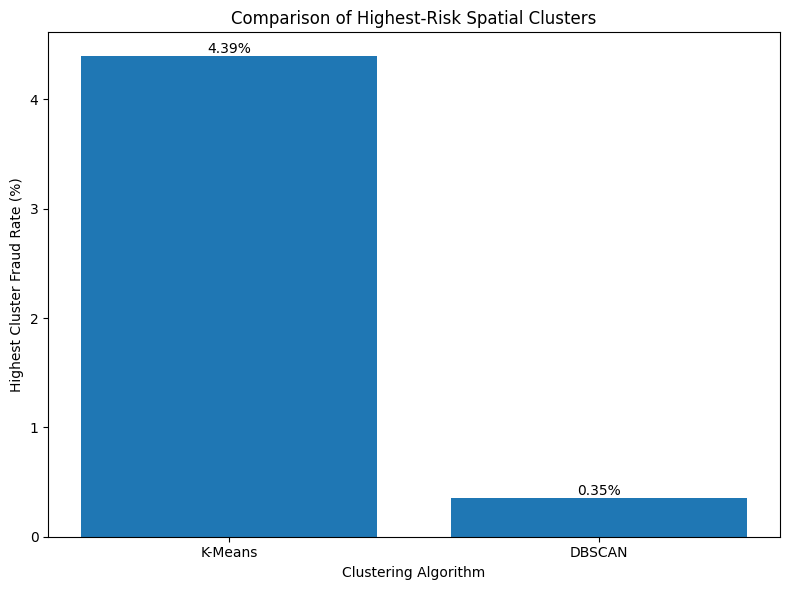

In [ ]:
# Cell 36 — K-Means vs DBSCAN Fraud Rate

plt.figure(figsize=(8, 6))

algorithms = clustering_comparison["Algorithm"]
fraud_rates = clustering_comparison["Fraud Rate (%)"]

bars = plt.bar(
    algorithms,
    fraud_rates
)

plt.ylabel("Highest Cluster Fraud Rate (%)")
plt.xlabel("Clustering Algorithm")
plt.title(
    "Comparison of Highest-Risk Spatial Clusters"
)

for bar, value in zip(bars, fraud_rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
# Cell 37 — City-Level Fraud Hotspot Analysis

city_summary = (
    df.groupby(
        ["city", "state"]
    )
    .agg(
        total_transactions=(
            "transaction_id",
            "count"
        ),
        latitude=(
            "latitude",
            "mean"
        ),
        longitude=(
            "longitude",
            "mean"
        )
    )
    .reset_index()
)

fraud_city = (
    df[
        df["fraud_type"] != "Normal"
    ]
    .groupby(
        ["city", "state"]
    )
    .size()
    .reset_index(
        name="fraud_transactions"
    )
)

city_summary = city_summary.merge(
    fraud_city,
    on=["city", "state"],
    how="left"
)

city_summary["fraud_transactions"] = (
    city_summary["fraud_transactions"]
    .fillna(0)
)

city_summary["fraud_rate_%"] = (
    city_summary["fraud_transactions"]
    /
    city_summary["total_transactions"]
    * 100
)

city_summary = city_summary.sort_values(
    "fraud_rate_%",
    ascending=False
)

display(city_summary)

,city,state,total_transactions,latitude,longitude,fraud_transactions,fraud_rate_%
16,New Delhi,Delhi,26,28.613900,77.209000,26.0,100.000000
6,Delhi,Delhi,13190,28.612655,77.218364,1250.0,9.476876
4,Chennai,Tamil Nadu,2206,13.072919,80.282009,27.0,1.223935
12,Kolkata,West Bengal,6631,22.574149,88.356390,24.0,0.361936
0,Ahmedabad,Gujarat,6564,23.003044,72.573133,23.0,0.350396
14,Mumbai,Maharashtra,5893,19.087503,72.888946,19.0,0.322416
9,Jaipur,Rajasthan,9639,26.905934,75.779521,27.0,0.280112
7,Hyderabad,Telangana,11815,17.387118,78.495093,31.0,0.262378
1,Bengaluru,Karnataka,11116,12.978804,77.595492,23.0,0.206909
3,Chandigarh,Chandigarh,6804,30.738921,76.780870,0.0,0.000000


In [ ]:
# Cell 38 — Top Spatial Fraud Hotspots

top_hotspots = (
    city_summary
    .sort_values(
        "fraud_rate_%",
        ascending=False
    )
    .head(10)
)

display(
    top_hotspots[
        [
            "city",
            "state",
            "total_transactions",
            "fraud_transactions",
            "fraud_rate_%"
        ]
    ]
)

,city,state,total_transactions,fraud_transactions,fraud_rate_%
16,New Delhi,Delhi,26,26.0,100.000000
6,Delhi,Delhi,13190,1250.0,9.476876
4,Chennai,Tamil Nadu,2206,27.0,1.223935
12,Kolkata,West Bengal,6631,24.0,0.361936
0,Ahmedabad,Gujarat,6564,23.0,0.350396
14,Mumbai,Maharashtra,5893,19.0,0.322416
9,Jaipur,Rajasthan,9639,27.0,0.280112
7,Hyderabad,Telangana,11815,31.0,0.262378
1,Bengaluru,Karnataka,11116,23.0,0.206909
3,Chandigarh,Chandigarh,6804,0.0,0.000000


In [ ]:
# Cell 39 — Top Cities by Fraud Transaction Count

top_fraud_cities = (
    city_summary
    .sort_values(
        "fraud_transactions",
        ascending=False
    )
    .head(10)
)

display(
    top_fraud_cities[
        [
            "city",
            "state",
            "total_transactions",
            "fraud_transactions",
            "fraud_rate_%"
        ]
    ]
)

,city,state,total_transactions,fraud_transactions,fraud_rate_%
6,Delhi,Delhi,13190,1250.0,9.476876
7,Hyderabad,Telangana,11815,31.0,0.262378
4,Chennai,Tamil Nadu,2206,27.0,1.223935
9,Jaipur,Rajasthan,9639,27.0,0.280112
16,New Delhi,Delhi,26,26.0,100.000000
12,Kolkata,West Bengal,6631,24.0,0.361936
0,Ahmedabad,Gujarat,6564,23.0,0.350396
1,Bengaluru,Karnataka,11116,23.0,0.206909
14,Mumbai,Maharashtra,5893,19.0,0.322416
3,Chandigarh,Chandigarh,6804,0.0,0.000000


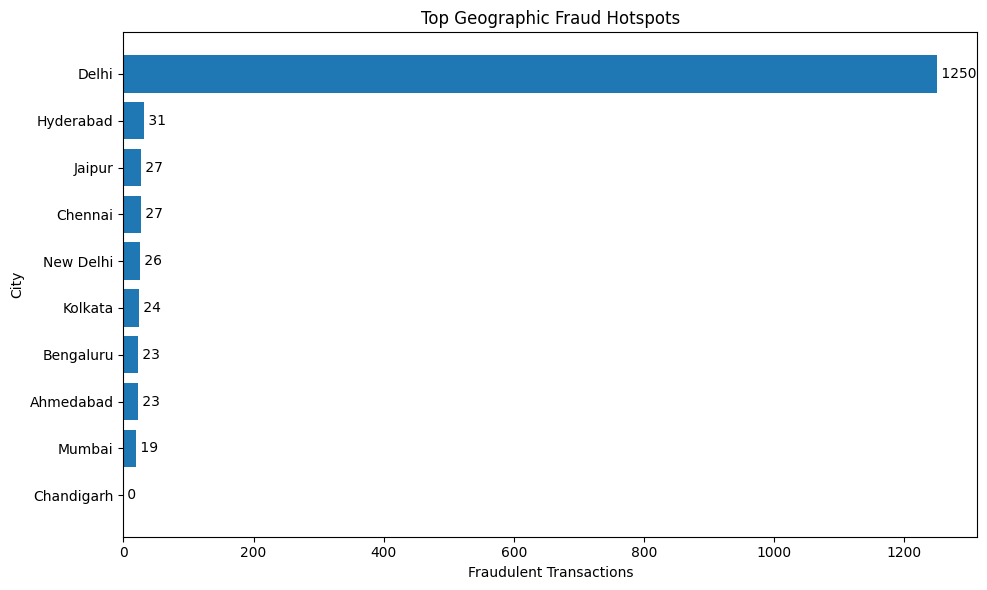

In [ ]:
# Cell 40 — Fraud Hotspot Visualization

plot_df = (
    city_summary
    .sort_values(
        "fraud_transactions",
        ascending=False
    )
    .head(10)
    .sort_values("fraud_transactions")
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    plot_df["city"],
    plot_df["fraud_transactions"]
)

plt.xlabel("Fraudulent Transactions")
plt.ylabel("City")
plt.title(
    "Top Geographic Fraud Hotspots"
)

for bar, value in zip(
    bars,
    plot_df["fraud_transactions"]
):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {int(value)}",
        va="center"
    )

plt.tight_layout()
plt.show()

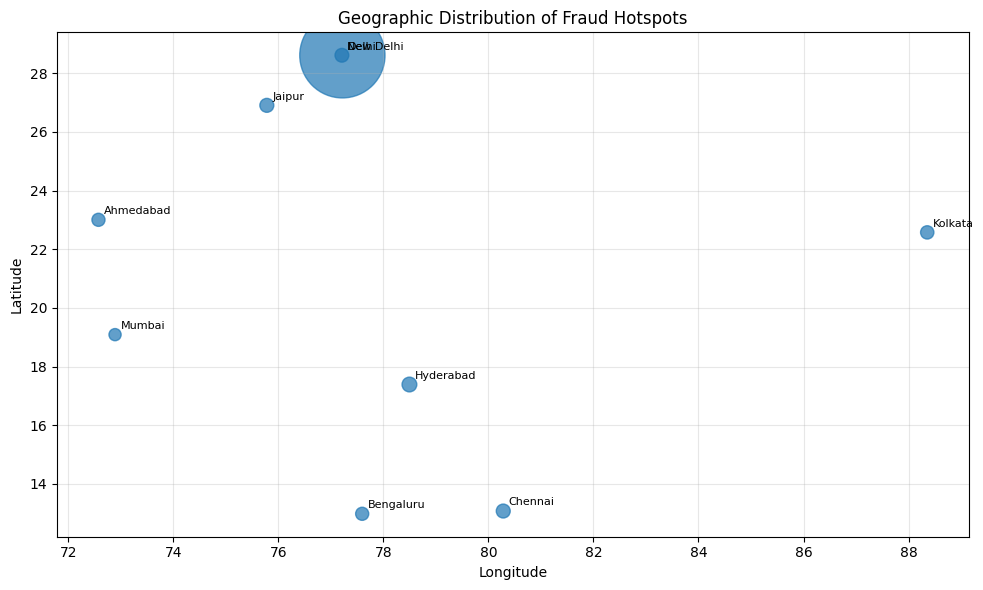

In [ ]:
# Cell 41 — Geographic Fraud Hotspot Map

hotspot_map = (
    city_summary[
        city_summary["fraud_transactions"] > 0
    ]
    .copy()
)

plt.figure(figsize=(10, 6))

plt.scatter(
    hotspot_map["longitude"],
    hotspot_map["latitude"],
    s=hotspot_map["fraud_transactions"] * 3 + 20,
    alpha=0.7
)

for _, row in hotspot_map.iterrows():

    plt.annotate(
        row["city"],
        (
            row["longitude"],
            row["latitude"]
        ),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Geographic Distribution of Fraud Hotspots"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Cell 42 — Fraud Types Across Cities

city_fraud_types = pd.crosstab(
    df["city"],
    df["fraud_type"]
)

city_fraud_types = (
    city_fraud_types
    .drop(
        columns="Normal",
        errors="ignore"
    )
    .sort_values(
        by=list(
            city_fraud_types.columns[
                city_fraud_types.columns != "Normal"
            ]
        ),
        ascending=False
    )
)

display(
    city_fraud_types.head(15)
)

fraud_type,Circular,Layering,Mule,RapidGeographicMovement,Smurfing,Structuring
city,,,,,,
Delhi,200,200,300,0,250,300
Hyderabad,0,0,0,31,0,0
Chennai,0,0,0,27,0,0
Jaipur,0,0,0,27,0,0
New Delhi,0,0,0,26,0,0
Kolkata,0,0,0,24,0,0
Ahmedabad,0,0,0,23,0,0
Bengaluru,0,0,0,23,0,0
Mumbai,0,0,0,19,0,0


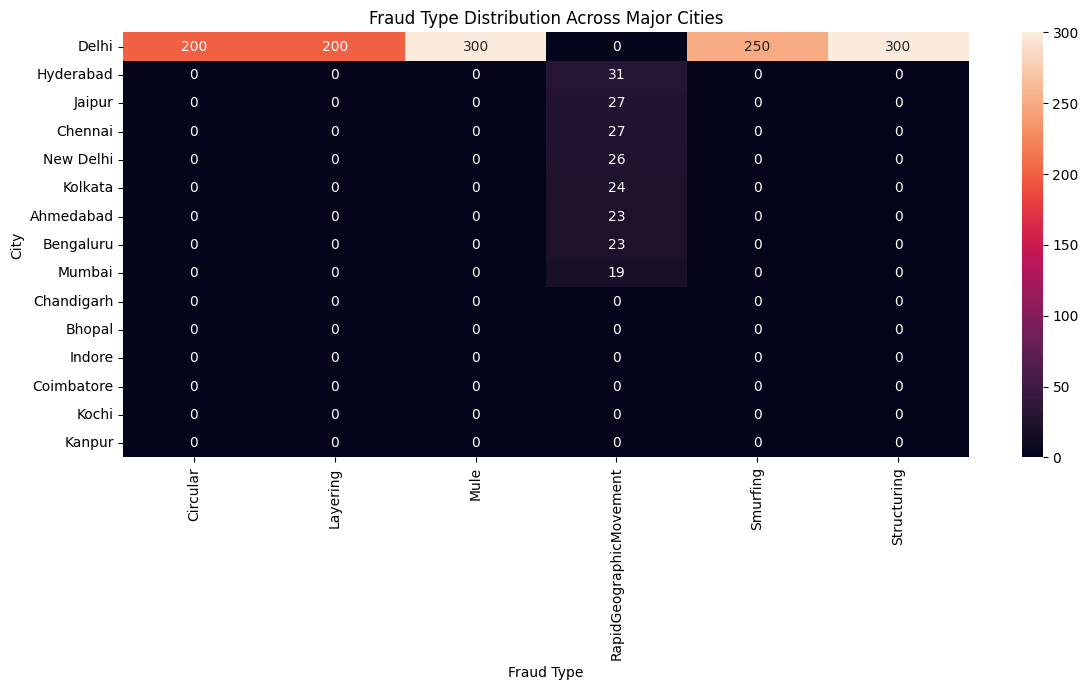

In [ ]:
# Cell 43 — City vs Fraud Type Heatmap

import seaborn as sns

heatmap_data = pd.crosstab(
    df["city"],
    df["fraud_type"]
)

heatmap_data = heatmap_data.drop(
    columns="Normal",
    errors="ignore"
)

top_cities = (
    heatmap_data.sum(axis=1)
    .sort_values(
        ascending=False
    )
    .head(15)
    .index
)

heatmap_data = heatmap_data.loc[
    top_cities
]

plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="g"
)

plt.title(
    "Fraud Type Distribution Across Major Cities"
)

plt.xlabel("Fraud Type")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 44 — Spatial Mining Summary

spatial_summary = pd.DataFrame({
    "Analysis": [
        "Transaction Records",
        "Unique Cities",
        "RapidGeo Patterns",
        "RapidGeo Best Precision",
        "RapidGeo Best Recall",
        "RapidGeo Best F1",
        "K-Means Clusters",
        "Highest K-Means Fraud Rate",
        "DBSCAN Clusters",
        "Highest DBSCAN Fraud Rate"
    ],
    "Result": [
        len(df),
        df["city"].nunique(),
        len(planted_patterns),
        f"{best_threshold['precision_%']:.2f}%",
        f"{best_threshold['recall_%']:.2f}%",
        f"{best_threshold['F1_%']:.2f}%",
        K,
        f"{kmeans_highest['fraud_rate_%']:.2f}%",
        dbscan_summary[
            dbscan_summary["dbscan_cluster"] != -1
        ].shape[0],
        f"{dbscan_highest['fraud_rate_%']:.2f}%"
    ]
})

display(spatial_summary)

,Analysis,Result
0,Transaction Records,149994
1,Unique Cities,21
2,RapidGeo Patterns,50
3,RapidGeo Best Precision,96.00%
4,RapidGeo Best Recall,96.00%
5,RapidGeo Best F1,96.00%
6,K-Means Clusters,8
7,Highest K-Means Fraud Rate,4.39%
8,DBSCAN Clusters,19
9,Highest DBSCAN Fraud Rate,0.35%


In [ ]:
# Cell 45 — Save Spatial Mining Outputs

output_path = (
    "/content/drive/MyDrive/"
    "AML_Project/outputs/"
)

import os

os.makedirs(
    output_path,
    exist_ok=True
)

city_summary.to_csv(
    output_path + "spatial_city_hotspots.csv",
    index=False
)

cluster_summary.to_csv(
    output_path + "kmeans_spatial_clusters.csv",
    index=False
)

dbscan_summary.to_csv(
    output_path + "dbscan_spatial_clusters.csv",
    index=False
)

clustering_comparison.to_csv(
    output_path + "spatial_clustering_comparison.csv",
    index=False
)

pattern_threshold_results.to_csv(
    output_path + "rapidgeo_threshold_evaluation.csv",
    index=False
)

spatial_summary.to_csv(
    output_path + "spatial_mining_summary.csv",
    index=False
)

print("All spatial mining results saved successfully!")

All spatial mining results saved successfully!
